# Orla - análise dos resultados
**Tony Khaled Osman - RM 553050**  
**Inacia dos Santos Silva - RM 553401**

Cognitive Computing, Computer Vision and IoT Systems - Arnaldo Jr.

Este notebook distingue testes de lógica com medidas sintéticas, ensaio de processamento de um retrato público e avaliação humana. Os primeiros não demonstram acurácia de movimentos em pessoas. Nenhuma imagem prévia é usada para autenticar alguém.

Para renovar as evidências: executar `python codigo/testar_logica.py`, `python codigo/avaliar_imagens.py` e, após rotulagem humana, `python codigo/avaliar_sessoes.py`. Em seguida executar as células deste notebook. Os tempos dependem do equipamento.

In [1]:
from pathlib import Path
from matplotlib import pyplot as plt
import sys

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "codigo"))
from avaliar_sessoes import ler_tabela

assert (RAIZ / "codigo/metodos.py").exists(), "Abra o notebook na pasta do projeto."
testes = ler_tabela(RAIZ / "resultados/testes_logica.csv")
ensaios = ler_tabela(RAIZ / "resultados/ensaio_imagens.csv")
print("Testes de lógica:", len(testes))
print("Execuções de processamento:", len(ensaios))

Testes de lógica: 26
Execuções de processamento: 30


## 1. Testes determinísticos
Medidas artificiais exercitam estados, tempo, EAR e regras. O critério esperado foi definido no script. Passar esses testes demonstra o comportamento do código nesses cenários; não comprova que o detector extrairá as mesmas medidas de rostos reais.

In [2]:
for teste in testes:
    print(teste["resultado"], "-", teste["teste"])
print("Passaram:", sum(t["resultado"] == "PASSOU" for t in testes), "/", len(testes))

PASSOU - EAR conhecido
PASSOU - Olho degenerado
PASSOU - Escala e translacao
PASSOU - Pontos invalidos
PASSOU - Regra ESQUERDA
PASSOU - Regra DIREITA
PASSOU - Regra CIMA
PASSOU - Regra BAIXO
PASSOU - Regra CENTRO
PASSOU - Regra AMBIGUO
PASSOU - Fluxo completo
PASSOU - Movimento errado
PASSOU - Lacuna temporal
PASSOU - Olhos fechados demais
PASSOU - Perda de rosto na piscada
PASSOU - Prazo da etapa
PASSOU - Relogio repetido
PASSOU - Observacao invalida
PASSOU - Comecar de olhos fechados
PASSOU - Referencia numerica neutra
PASSOU - EAR relativo
PASSOU - Calibracao perde face
PASSOU - Calibracao instavel
PASSOU - Direcao independente do EAR
PASSOU - Centro exige olhos abertos
PASSOU - Perda de face ainda bloqueia direcao
Passaram: 26 / 26


## 2. EAR ilustrativo
A curva abaixo é uma sequência numérica construída para explicar o evento abrir-fechar-abrir. Não é uma pessoa, gravação ou evidência de desempenho humano. A adaptação do Lab12 exige reabertura e usa limiares distintos para reduzir oscilações.

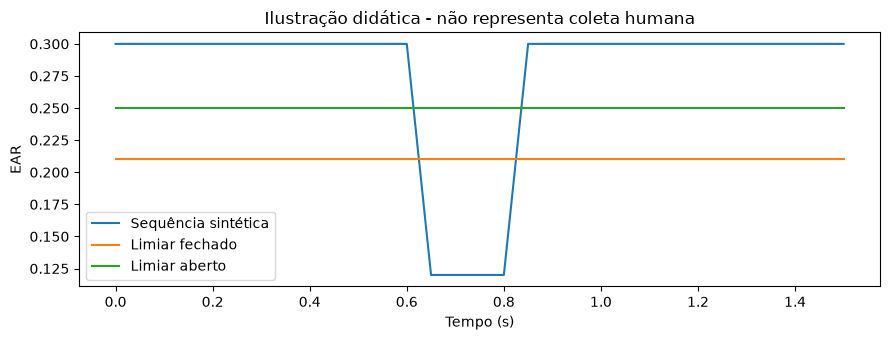

In [3]:
from configuracao import PARAMETROS
instantes = [i * 0.05 for i in range(31)]
ear_ilustrativo = [0.30 if t < 0.65 or t >= 0.85 else 0.12 for t in instantes]
plt.figure(figsize=(9, 3.5))
plt.plot(instantes, ear_ilustrativo, label="Sequência sintética")
plt.plot(instantes, [PARAMETROS["ear_fechado"]] * len(instantes), label="Limiar fechado")
plt.plot(instantes, [PARAMETROS["ear_aberto"]] * len(instantes), label="Limiar aberto")
plt.xlabel("Tempo (s)")
plt.ylabel("EAR")
plt.title("Ilustração didática - não representa coleta humana")
plt.legend()
plt.tight_layout()
plt.savefig(RAIZ / "resultados/ear_ilustrativo.png", dpi=160)
plt.show()

## 3. Ensaio de imagens
Apenas **um retrato público NASA** origina a imagem original e duas versões escurecidas. Há ainda controles sem face e com duas cópias. São cinco cenários, dois pré-processamentos e três repetições de tempo: 30 execuções, não 30 pessoas ou 30 fotografias independentes.

A referência de contagem foi estabelecida visualmente. Igualdade de contagens não garante que cada caixa corresponda ao rosto correto; não calculamos precisão espacial ou identidade.

In [4]:
casos = []
for linha in ensaios:
    if linha["caso"] not in casos:
        casos.append(linha["caso"])
for caso in casos:
    for modo in ("0", "1"):
        linhas = [r for r in ensaios if r["caso"] == caso and r["equalizado"] == modo]
        tempos = [float(r["processamento_ms"]) for r in linhas]
        esperado = linhas[0]["faces_esperadas"]
        contagens = [int(r["faces_detectadas"]) for r in linhas]
        print(caso, "equalizado=" + modo, "esperado=" + esperado,
              "observado=", contagens, "média_ms=", round(sum(tempos) / len(tempos), 2))

original equalizado=0 esperado=1 observado= [1, 1, 1] média_ms= 29.64
original equalizado=1 esperado=1 observado= [2, 2, 2] média_ms= 26.45
escura_045 equalizado=0 esperado=1 observado= [1, 1, 1] média_ms= 27.58
escura_045 equalizado=1 esperado=1 observado= [2, 2, 2] média_ms= 27.23
escura_015 equalizado=0 esperado=1 observado= [1, 1, 1] média_ms= 28.62
escura_015 equalizado=1 esperado=1 observado= [2, 2, 2] média_ms= 28.48
sem_face equalizado=0 esperado=0 observado= [0, 0, 0] média_ms= 25.69
sem_face equalizado=1 esperado=0 observado= [0, 0, 0] média_ms= 26.2
duas_faces equalizado=0 esperado=2 observado= [3, 3, 3] média_ms= 50.27
duas_faces equalizado=1 esperado=2 observado= [3, 3, 3] média_ms= 47.68


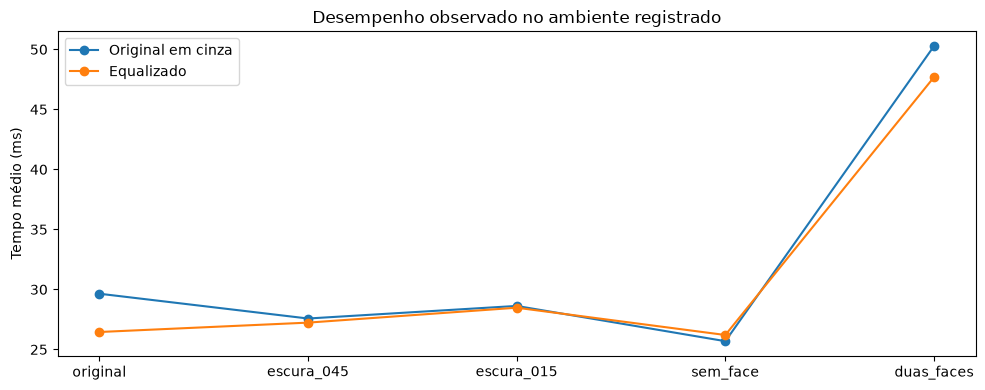

In [5]:
plt.figure(figsize=(10, 4))
for modo, nome in [("0", "Original em cinza"), ("1", "Equalizado")]:
    medias = []
    for caso in casos:
        valores = [float(r["processamento_ms"]) for r in ensaios
                   if r["caso"] == caso and r["equalizado"] == modo]
        medias.append(sum(valores) / len(valores))
    plt.plot(casos, medias, marker="o", label=nome)
plt.ylabel("Tempo médio (ms)")
plt.title("Desempenho observado no ambiente registrado")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Interpretação
Equalização pode alterar tanto a detecção quanto os falsos positivos. A escolha do modo deve seguir os resultados e o contexto. O detector frontal tem limites em inclinação, oclusão e iluminação. Não usar os ensaios de imagem estática para concluir que quatro movimentos ou piscadas foram validados.

Razões horizontais/verticais são heurísticas 2D; não são yaw/pitch em graus, embeddings ou verificação de identidade.

## 5. Avaliação humana
Preencher `dados/tentativas.csv` com observação independente e executar `avaliar_sessoes.py`. Uma previsão não pode ser usada como seu próprio rótulo verdadeiro. Não misturar participantes de ajuste com os de teste, nem contabilizar milhares de frames como participantes independentes.

In [6]:
arquivo_humano = RAIZ / "resultados/avaliacao_humana.csv"
humanos = ler_tabela(arquivo_humano) if arquivo_humano.exists() else []
print("Tentativas humanas rotuladas:", len(humanos))
if not humanos:
    print("SEM AVALIAÇÃO HUMANA ROTULADA. Não há acurácia humana a declarar.")
else:
    for grupo in ("DESENVOLVIMENTO", "TESTE"):
        linhas = [r for r in humanos if r["grupo"] == grupo]
        positivas = [r for r in linhas if r["positiva"] == "1"]
        negativas = [r for r in linhas if r["positiva"] == "0"]
        print(grupo, "reconhecidas", sum(r["aceitou"] == "1" for r in positivas), "/", len(positivas),
              "negativas aceitas", sum(r["aceitou"] == "1" for r in negativas), "/", len(negativas))

Tentativas humanas rotuladas: 0
SEM AVALIAÇÃO HUMANA ROTULADA. Não há acurácia humana a declarar.


## 6. Piloto funcional final
No piloto final de 10/11/2026 com um participante, cinco tentativas foram calibradas: três concluíram as dez etapas e duas foram reiniciadas. As conclusões levaram 13,351 s, 22,494 s e 17,997 s após a calibração. O participante confirmou correspondência dos avanços com movimentos leves. Trata-se de autorrelato global e eventos do programa, sem rótulos independentes por ação; não estimamos acurácia humana.

In [7]:
piloto = ler_tabela(RAIZ / "resultados/piloto_resumo.csv")
for tentativa in piloto:
    print("Tentativa", tentativa["tentativa"], tentativa["status"], "etapas:", tentativa["etapas"], "duração após ajuste (s):", tentativa["duracao_s"])
print("Autorrelato: movimentos leves e avanços correspondentes. Sem rotulagem independente; não calcular acurácia a partir destas conclusões.")

Tentativa 1 concluida etapas: 10 duração após ajuste (s): 13.351
Tentativa 2 concluida etapas: 10 duração após ajuste (s): 22.494
Tentativa 3 interrompida etapas: 1 duração após ajuste (s): 
Tentativa 4 interrompida etapas: 2 duração após ajuste (s): 
Tentativa 5 concluida etapas: 10 duração após ajuste (s): 17.997
Autorrelato: movimentos leves e avanços correspondentes. Sem rotulagem independente; não calcular acurácia a partir destas conclusões.


## 7. Fontes
- Professor: [Lab12 - dlib e EAR](https://arnaldojr.github.io/cognitivecomputing/aulas/PDI/lab16/dlib2.html).
- Professor: [Lab03 - histogramas, equalização e webcam](https://arnaldojr.github.io/cognitivecomputing/aulas/PDI/lab03/atividade3.html).
- Professor: [Lab01 - representação de imagens](https://arnaldojr.github.io/cognitivecomputing/aulas/PDI/lab01/IntroPID.html).
- Imagem: NASA/Eileen Collins, acervo scikit-image, domínio público; ver `dados/LEIA-ME.md`.

O uso de modelo pré-treinado foi ensinado; não houve treinamento de rede pelos autores. As regras de direção e a sequência de interação são adaptações autorais.